**Calibrating ensemble classifiers on their member estimator's hold-out sets**

This notebook shows how to

1. Calibrate a single classification model with Mother methods
2. (Calibrate an ensemble by adjusting each member estimator's predictions) Will be included.

Mother provides calibrator classes for *probability calibration* and *uncertainty calibration*. The calibrator families work towards two different goals, respectively:

> Probability calibration

Probability calibration in classification aims for adjusting raw class probabilities produced by the model, so that empirical true likelihoods are reflected. For example, if a well-calibrated classifier predicts an event with 80% probability for specific cases, the event is actually observed in 80% of these cases. Many models are badly calibrated, e.g. by predicting overconfident probabilities. An overconfident model can still be highly accurate in its predictions, but reliable probabilistic predictions are crucial whenever class probabilities are used for informed decision-making or when other methods (like uncertainty quantification) rely on class probabilities.


> Uncertainty calibration

Uncertainty calibration aims for transforming uncertainty estimates into error probabilities, so that uncertainty scores can be interpreted individually. An uncertainty estimate alone often has no meaning without comparison within the uncertainty distribution. If use cases go beyond ranking within a group, uncertainty calibration helps to estimate the resulting error probability from uncertainty scores.


> What is a calibrator?

For both calibration families, the calibrator is an estimator itself, that maps a specific input (e.g. the probability distribution across classes, or total uncertainty) to a specific output (e.g. calibrated probabilities, or error likelihoods). The calibrator is applied post-hoc to a model's predictions. Therefore, it needs a seperate training set than the original model was trained on. This training set is referred to as "calibration set". In the special case of CV ensembles, hold-out folds of member estimators can be used as calibration sets, as each member estimator was trained on the remaining folds and never sees the hold-out fold during training.

In [ ]:
import inspect

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import train_test_split

from mother import ml
import mother.calibration.probability_calibration as pcal
import mother.calibration.uncertainty_calibration as ucal

/home/sagemaker-user/projects/MotherML/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Calibration of single models

### Preparation: Load and split example data & train model

In [4]:
df_data, df_targets = load_breast_cancer(return_X_y=True, as_frame=True)
X_train_, X_test, y_train_, y_test = train_test_split(
    df_data, df_targets, test_size=0.25, random_state=42, stratify=df_targets
)
X_train, X_cal, y_train, y_cal = train_test_split(
    X_train_, y_train_, test_size=0.25, random_state=42, stratify=y_train_
)

print(f"Loaded breast cancer dataset with {df_data.shape[0]} samples and {df_data.shape[1]} features.\n")
print(f"Split into {X_train.shape[0]} train and {X_test.shape[0]} test samples.")
print(f"{X_cal.shape[0]} samples are held out completely for calibration.")

Loaded breast cancer dataset with 569 samples and 30 features.

Split into 319 train and 143 test samples.
107 samples are held out completely for calibration.


### Single model setup and training

In [5]:
model = ml.CatboostClassifierMother(random_seed=42, verbose=False)
model.fit(X_train, y_train)
model_prediction_raw = model.predict_uncertainty(X_test)

### Probability calibration

In [6]:
p_calibrators = {
    name: calibrator()
    for name, calibrator in inspect.getmembers(pcal, inspect.isclass)
    if calibrator.__module__ == pcal.__name__
}

print(f"Available probability calibrators: {list(p_calibrators.keys())}")

Available probability calibrators: ['PlattProbabilityCalibrator', 'VennAbersProbabilityCalibrator']


In [7]:
cal_predictions = model.predict_uncertainty(X_cal)
proba_cols = ["proba_0", "proba_1"]

# calibration based on proba_1
cal_probas = cal_predictions[proba_cols]
calibrated_probas = {}
for name, calibrator in p_calibrators.items():
    calibrator.fit(exog=cal_probas, endog=y_cal)
    calibrated_probas[name] = calibrator.predict_proba(exog=model_prediction_raw[proba_cols])

In [8]:
cal_predictions.head()

,pred,proba_0,proba_1,mean_predictions,knowledge_uncertainty,data_uncertainty,total_uncertainty
224,1,0.001444,0.998556,None,0.000101,0.016008,0.016109
323,0,0.999957,0.000043,None,0.000002,0.000701,0.000704
32,0,0.999960,0.000040,None,0.000002,0.000673,0.000675
11,0,0.999900,0.000100,None,0.000008,0.001606,0.001614
50,1,0.000371,0.999629,None,0.000040,0.005304,0.005344


### Uncertainty calibration

We calibrate uncertainty based on two uncertainty features: knowledge uncertainty and data uncertainty.

Reminder: Uncertainty calibration predicts expected error probabilities based on the calibration set.

In [9]:
u_calibrators = {
    name: calibrator()
    for name, calibrator in inspect.getmembers(ucal, inspect.isclass)
    if calibrator.__module__ == ucal.__name__
}

print(f"Available uncertainty calibrators: {list(u_calibrators.keys())}")

Available uncertainty calibrators: ['BaggingIRErrorCalibrator', 'GLMErrorCalibrator', 'IsotonicRegressionErrorCalibrator', 'RandomForestErrorCalibrator']


In [10]:
# calibration based on uncertainty features (cal set for calibrator fitting)
feature_cols = ["knowledge_uncertainty", "data_uncertainty"]
cal_uncertainties = cal_predictions[feature_cols]
cal_error = cal_predictions["pred"].ne(y_cal).astype(int)

# inference on test set
test_uncertainties = model_prediction_raw[feature_cols]
calibrated_error_probs = {}
oob_scores = {}
for name, calibrator in u_calibrators.items():
    calibrator.fit(exog=cal_uncertainties, endog=cal_error)
    calibrated_error_probs[name] = calibrator.predict(exog=test_uncertainties)
    if hasattr(calibrator, "oob_score"):
        oob_scores[name] = calibrator.oob_score
    else:
        oob_scores[name] = None

In [11]:
oob_scores

{'BaggingIRErrorCalibrator': -0.0731128924583615,
 'GLMErrorCalibrator': None,
 'IsotonicRegressionErrorCalibrator': None,
 'RandomForestErrorCalibrator': -0.3025647707574868}

> Negative OOB scores indicate no improvement compared to the "mean" model. Could be due to small calibration dataset that is bootstrapped for OOB computation.

### Evaluation

#### Calibration of test probabilities

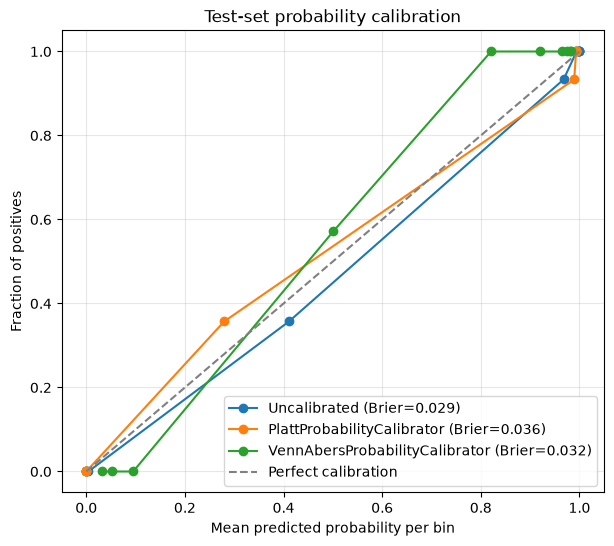

In [12]:
y_true = y_test.to_numpy()
raw_proba = model_prediction_raw["proba_1"].to_numpy()

plt.figure(figsize=(7, 6))

for name, probabilities in {
    "Uncalibrated": raw_proba,
    **{name: values[:, 1] for name, values in calibrated_probas.items()},
}.items():
    fraction_positive, mean_predicted = calibration_curve(y_true, probabilities, n_bins=10, strategy="quantile")
    brier_score = brier_score_loss(y_true, probabilities)
    plt.plot(mean_predicted, fraction_positive, marker="o", label=f"{name} (Brier={brier_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
plt.xlabel("Mean predicted probability per bin")
plt.ylabel("Fraction of positives")
plt.title("Test-set probability calibration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Calibration of test uncertainties

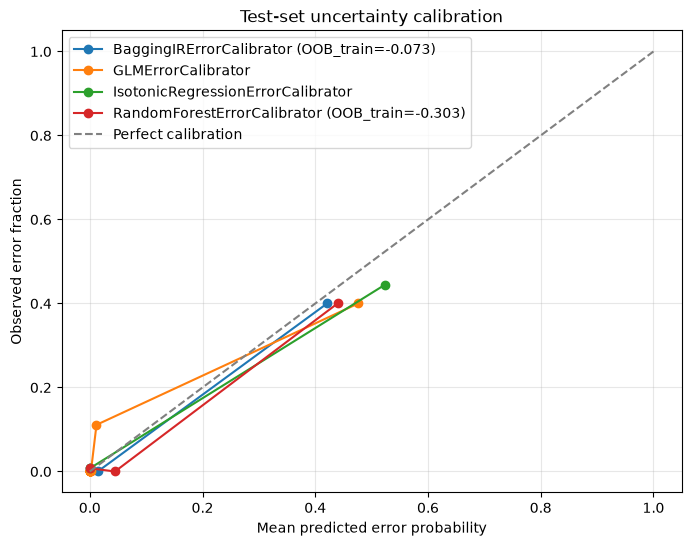

In [13]:
test_uncertainties = model_prediction_raw[["knowledge_uncertainty", "data_uncertainty"]]
test_errors = model_prediction_raw["pred"].ne(y_test).astype(int).to_numpy()

plt.figure(figsize=(8, 6))

for name, calibrator in u_calibrators.items():
    error_probabilities = calibrated_error_probs[name]
    fraction_errors, mean_predicted_error = calibration_curve(
        test_errors, error_probabilities, n_bins=15, strategy="quantile"
    )
    oob_score = oob_scores.get(name)
    if oob_score is not None:
        label = f"{name} (OOB_train={oob_score:.3f})"
    else:
        label = name

    plt.plot(
        mean_predicted_error,
        fraction_errors,
        marker="o",
        label=label,
    )

plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.xlabel("Mean predicted error probability")
plt.ylabel("Observed error fraction")
plt.title("Test-set uncertainty calibration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

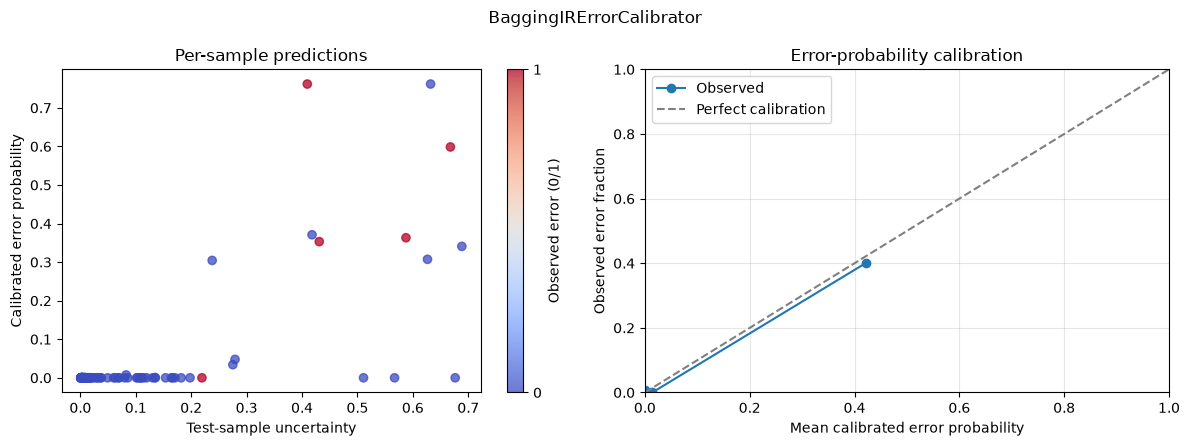

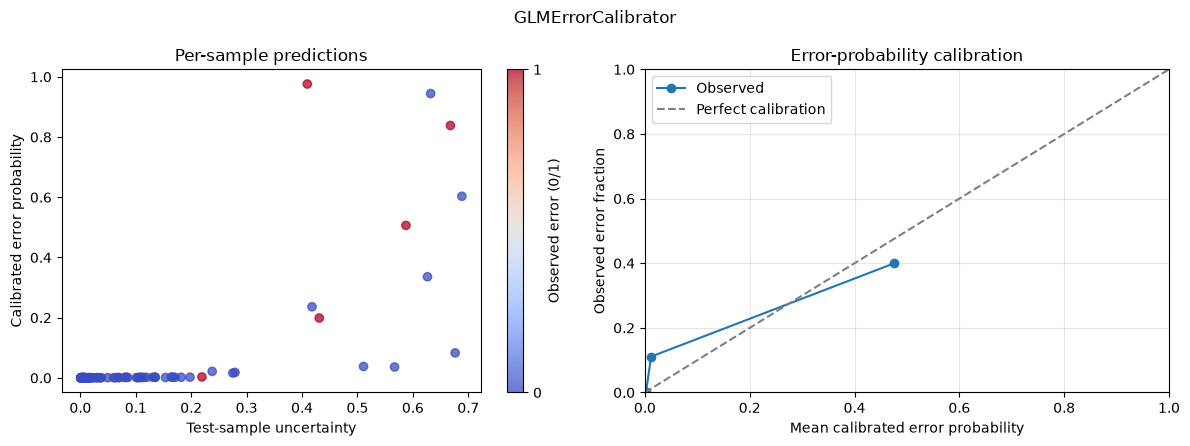

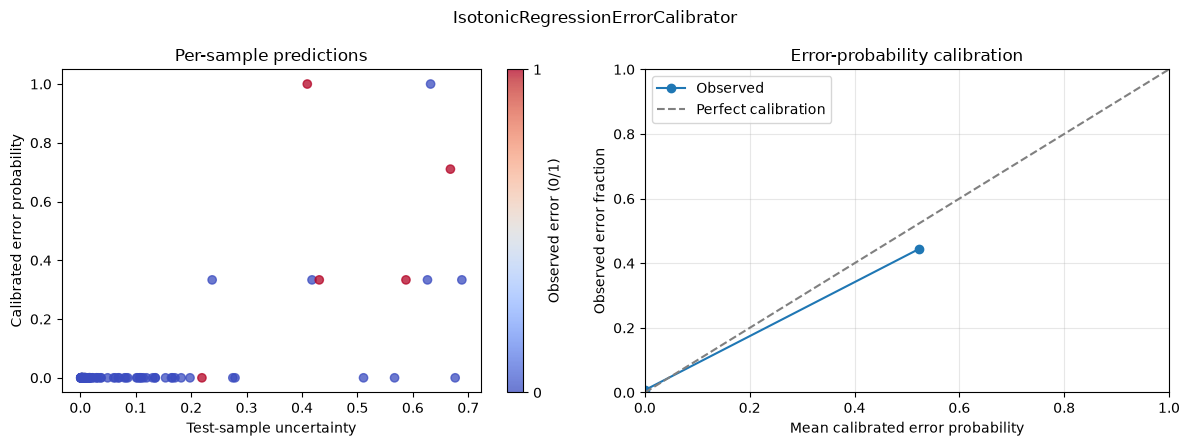

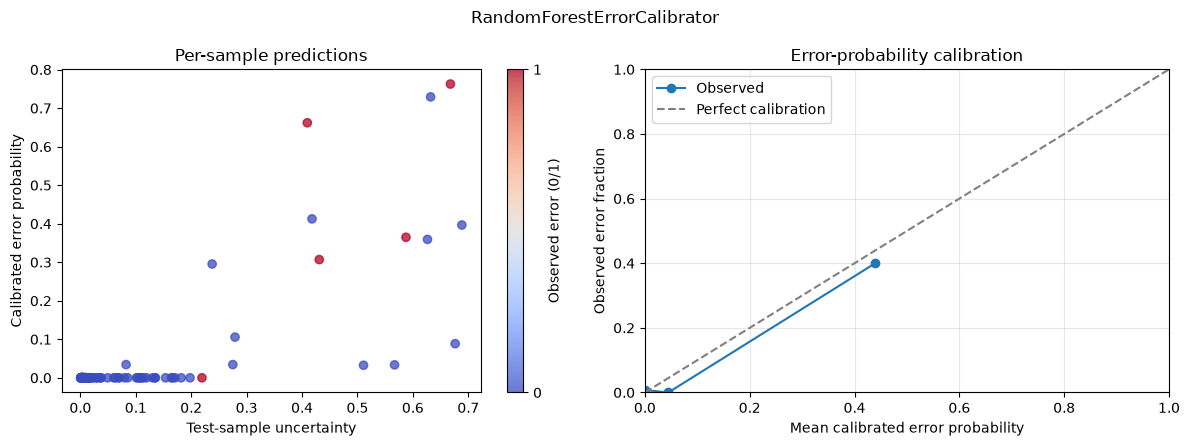

In [14]:
test_errors = model_prediction_raw["pred"].ne(y_test).astype(int).to_numpy()

if "total_uncertainty" in model_prediction_raw:
    sample_uncertainty = model_prediction_raw["total_uncertainty"].to_numpy()
else:
    sample_uncertainty = test_uncertainties.sum(axis=1).to_numpy()

for name, calibrator in u_calibrators.items():
    error_probabilities = calibrated_error_probs[name]

    fig, (ax_samples, ax_calibration) = plt.subplots(1, 2, figsize=(12, 4.5))

    # Each point is a test sample; color indicates whether it was misclassified.
    scatter = ax_samples.scatter(
        sample_uncertainty,
        error_probabilities,
        c=test_errors,
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        alpha=0.75,
    )
    ax_samples.set(
        xlabel="Test-sample uncertainty",
        ylabel="Calibrated error probability",
        title="Per-sample predictions",
    )
    fig.colorbar(scatter, ax=ax_samples, ticks=[0, 1], label="Observed error (0/1)")

    # Compare predicted error probabilities with observed error fractions.
    observed_fraction, mean_predicted = calibration_curve(
        test_errors, error_probabilities, n_bins=15, strategy="quantile"
    )
    ax_calibration.plot(mean_predicted, observed_fraction, "o-", label="Observed")
    ax_calibration.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax_calibration.set(
        xlabel="Mean calibrated error probability",
        ylabel="Observed error fraction",
        title="Error-probability calibration",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax_calibration.legend()
    ax_calibration.grid(True, alpha=0.3)

    fig.suptitle(name)
    fig.tight_layout()
    plt.show()

The cell displays one two-panel figure for each uncertainty calibrator:

- **Left:** Test samples’ uncertainty versus their calibrated error probability, colored by whether each prediction was actually wrong.
- **Right:** Predicted error probabilities compared with observed error fractions; the dashed diagonal marks perfect calibration.

Most samples receive low error probabilities, with a few higher scores. The calibration curves are sparse and vary by calibrator, so calibration quality differs across methods.